# Week 6: Decision Trees and Random Forests

## Introduction

Decision Tree and Random Forest are applied to all three marketing data sets. We will test the effectiveness of tree models on classification problems, study the consequences of overfitting, and detect significant predictive attributes. First of all, the Decision Tree models will be tested separately, and then we will apply the Random Forest models, which utilize several trees. Comparison of models’ performance will be done with the help of training and testing results, visualization, and hyperparameters adjustment. The results will also be compared with the previous classification models created during Weeks 4 and 5.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")

In [3]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing Dataset: (734, 19)


## Dataset 1: Digital Marketing Campaign

### Data Preparation

The Digital Marketing Campaign dataset contains 8,000 observations. Five marketing-related features will be used to predict whether a customer converts. The data will be divided into 80% training and 20% testing to evaluate how well the Decision Tree performs on unseen observations.

In [4]:
features1 = ["AdSpend", "ClickThroughRate", "WebsiteVisits", "TimeOnSite", "EmailClicks"]

X1 = df1[features1]
y1 = df1["Conversion"]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

print("Training:", X1_train.shape)
print("Testing:", X1_test.shape)
print("\nTarget Distribution:")
print(y1.value_counts())

Training: (6400, 5)
Testing: (1600, 5)

Target Distribution:
Conversion
1    7012
0     988
Name: count, dtype: int64


### Initial Decision Tree Model

A Decision Tree classifier was trained using the five selected marketing features. The initial model does not restrict tree depth, allowing us to examine its performance and determine whether overfitting occurs.

In [5]:
tree1 = DecisionTreeClassifier(random_state=42)
tree1.fit(X1_train, y1_train)

train_pred1 = tree1.predict(X1_train)
test_pred1 = tree1.predict(X1_test)

print("Training Accuracy:", round(accuracy_score(y1_train, train_pred1), 4))
print("Testing Accuracy:", round(accuracy_score(y1_test, test_pred1), 4))
print("Tree Depth:", tree1.get_depth())
print("Leaf Nodes:", tree1.get_n_leaves())

Training Accuracy: 1.0
Testing Accuracy: 0.7969
Tree Depth: 33
Leaf Nodes: 877


The accuracy obtained from the first Decision Tree is 100% during training and 79.69% during testing. The depth of the tree was 33, while the number of leaves was 877. This shows that the model is quite complicated. There is a significant disparity between the accuracy obtained from training and testing. This could be due to overfitting.

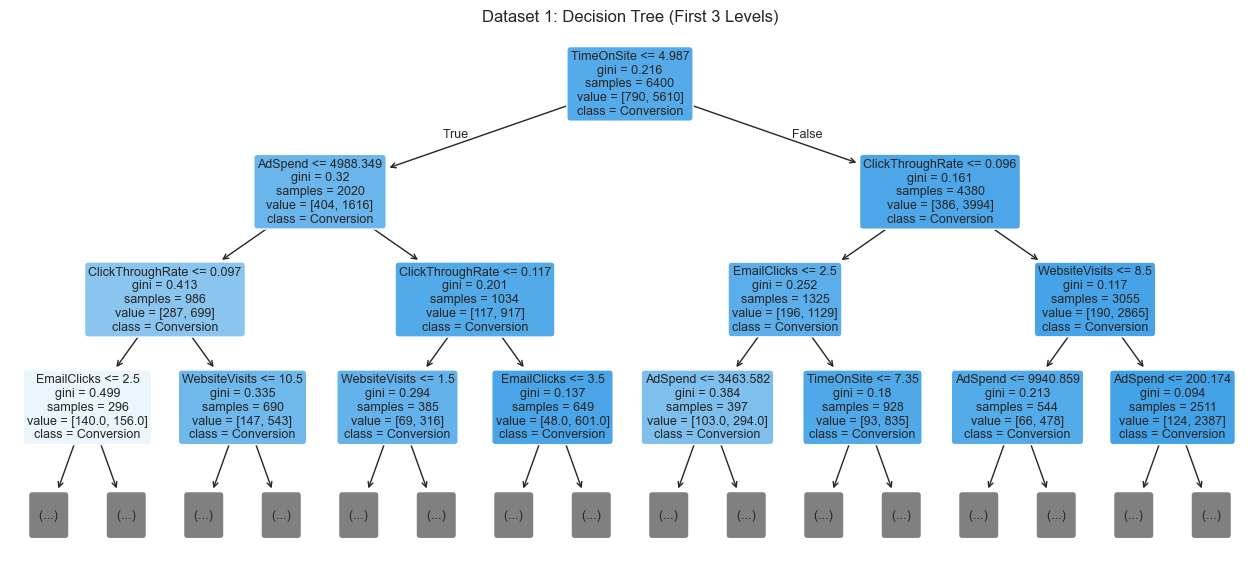

In [6]:
plt.figure(figsize=(16, 7))
plot_tree(tree1, feature_names=features1, class_names=["No Conversion", "Conversion"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Dataset 1: Decision Tree (First 3 Levels)")
plt.show()

The Decision Tree starts dividing customers using the TimeOnSite parameter, then divides them according to other parameters such as AdSpend, ClickThroughRate, EmailClicks, and WebsiteVisits. While this tree makes use of several parameters for dividing the observations, it is still noticeable that the nodes of the tree keep favoring the class called Conversion. This is an indication of the class imbalance within the dataset, which means that it will be hard for the model to find non-converting customers.

### Decision Tree Depth Comparison

Various maximum depths of trees were tested in order to explore the connection between model complexity and overfitting. Comparison of training and testing accuracies was done to see whether maximum tree depth restriction helps.

In [7]:
depth_results1 = []

for depth in [2, 3, 5, 7, 10, 15, 20, 30]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X1_train, y1_train)

    depth_results1.append({
        "Depth": depth,
        "Training Accuracy": accuracy_score(y1_train, model.predict(X1_train)),
        "Testing Accuracy": accuracy_score(y1_test, model.predict(X1_test))
    })

depth_results1 = pd.DataFrame(depth_results1)
depth_results1.round(4)

,Depth,Training Accuracy,Testing Accuracy
0,2,0.8766,0.8762
1,3,0.8766,0.8762
2,5,0.8878,0.8788
3,7,0.9008,0.8719
4,10,0.9339,0.8462
5,15,0.9734,0.8181
6,20,0.9939,0.8050
7,30,0.9995,0.7975


A comparison of various levels of maximum tree depths showed how model complexity affects overfitting. The maximum level of tree depth that yielded highest testing accuracy of 87.88% was 5. Training accuracy of the model at this level of tree depth was 88.78%. Increasing the tree depth increased the training accuracy towards 100%, while reducing testing accuracy to 79.75% for 30 levels of tree depth. It is evident that as the level of tree depth increases, models learn more specific patterns from the training dataset.

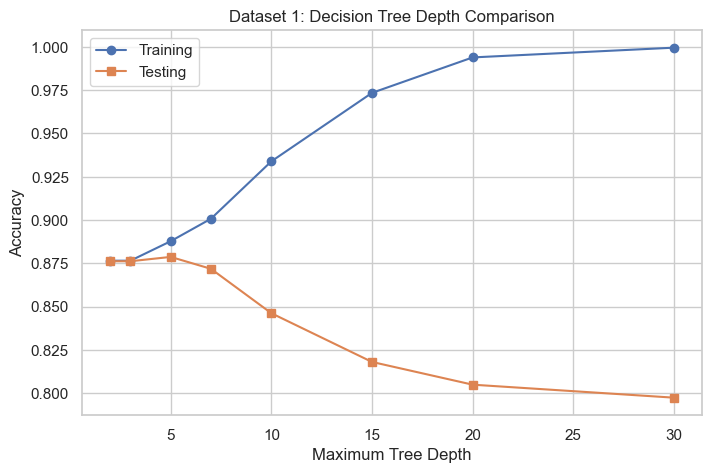

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(depth_results1["Depth"], depth_results1["Training Accuracy"], marker="o", label="Training")
plt.plot(depth_results1["Depth"], depth_results1["Testing Accuracy"], marker="s", label="Testing")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Dataset 1: Decision Tree Depth Comparison")
plt.legend()
plt.show()

### Random Forest Model

The training process of a Random Forest classifier involved 100 Decision Trees. As opposed to a single Decision Tree classifier, Random Forest involves the use of multiple trees together. This experiment seeks to establish if the use of multiple trees increases accuracy during testing.

In [9]:
rf1 = RandomForestClassifier(n_estimators=100, random_state=42)
rf1.fit(X1_train, y1_train)

rf_train_pred1 = rf1.predict(X1_train)
rf_test_pred1 = rf1.predict(X1_test)

print("Training Accuracy:", round(accuracy_score(y1_train, rf_train_pred1), 4))
print("Testing Accuracy:", round(accuracy_score(y1_test, rf_test_pred1), 4))
print("Precision:", round(precision_score(y1_test, rf_test_pred1), 4))
print("Recall:", round(recall_score(y1_test, rf_test_pred1), 4))
print("F1 Score:", round(f1_score(y1_test, rf_test_pred1), 4))

Training Accuracy: 1.0
Testing Accuracy: 0.8719
Precision: 0.8874
Recall: 0.9779
F1 Score: 0.9304


Training accuracy for the Random Forest was 100%, while testing accuracy was 87.19%. Though the former is a higher value than that of the original Decision Tree (79.69%), the latter is slightly lower than that of the Decision Tree with limited depth (87.88%). Besides, the Random Forest provided 88.74% of precision, 97.79% of recall, and 0.9304 F1 measure. Even though the model recognized most conversions well, its full training accuracy indicates that the issue of overfitting is still relevant. In general, using several trees helped to perform better than using only the Decision Tree.

### Random Forest Feature Importance

Feature importance was used in determining the marketing factors that played a significant role in predicting through the Random Forest. This provides an insight into the workings of the model in classification based on feature importance.

In [10]:
importance1 = pd.DataFrame({
    "Feature": features1,
    "Importance": rf1.feature_importances_
}).sort_values("Importance", ascending=False)

importance1.round(4)

,Feature,Importance
0,AdSpend,0.2484
1,ClickThroughRate,0.2439
3,TimeOnSite,0.2418
2,WebsiteVisits,0.1672
4,EmailClicks,0.0986


The results of Random Forest’s variable importance, it can be deduced that AdSpend (24.84%), ClickThroughRate (24.39%), and TimeOnSite (24.18%) were among the top three most important variables. In total, these three variables were responsible for about 73% of the variable importance. The WebsiteVisits variable provided 16.72% of the variable importance, whereas EmailClicks had the least importance of 9.86%.

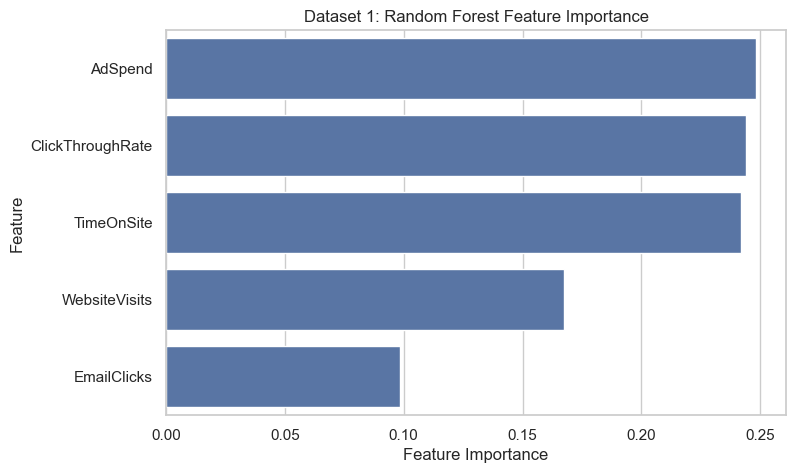

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=importance1, x="Importance", y="Feature")
plt.title("Dataset 1: Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

### Random Forest Hyperparameter Tuning

GridSearchCV with five folds was performed to test different settings of the Random Forest algorithm. Number of trees, maximum depth, and minimum samples at leaf level were changed to see if simplification of the model would help its performance. The F1 score was used as an evaluation metric taking into account both precision and recall.

In [12]:
param_grid1 = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10],
    "min_samples_leaf": [1, 5, 10]
}

grid1 = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid1, cv=5, scoring="f1", n_jobs=-1
)

grid1.fit(X1_train, y1_train)

print("Best Parameters:", grid1.best_params_)
print("Best Cross-Validation F1:", round(grid1.best_score_, 4))

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 10, 'n_estimators': 100}
Best Cross-Validation F1: 0.9368


The GridSearchCV process found the ideal depth of 10, the minimal number of 10 samples in each leaf and 100 trees for Random Forests model. The model obtained an F1 score of 0.9368 when cross validation was applied. Such parameters keep the complexity of each tree low and may decrease overfitting. The optimized model will now be assessed based on the testing data set.

In [13]:
best_rf1 = grid1.best_estimator_
tuned_train_pred1 = best_rf1.predict(X1_train)
tuned_test_pred1 = best_rf1.predict(X1_test)

print("Training Accuracy:", round(accuracy_score(y1_train, tuned_train_pred1), 4))
print("Testing Accuracy:", round(accuracy_score(y1_test, tuned_test_pred1), 4))
print("Precision:", round(precision_score(y1_test, tuned_test_pred1), 4))
print("Recall:", round(recall_score(y1_test, tuned_test_pred1), 4))
print("F1 Score:", round(f1_score(y1_test, tuned_test_pred1), 4))

Training Accuracy: 0.8931
Testing Accuracy: 0.8806
Precision: 0.8864
Recall: 0.9907
F1 Score: 0.9357


Hyperparameter tuning improved the Random Forest's testing accuracy from 87.19% to 88.06% and increased its F1 score from 0.9304 to 0.9357. Training accuracy decreased from 100% to 89.31%, suggesting that limiting tree complexity helped reduce overfitting. The tuned model also achieved a recall of 99.07%, correctly identifying most customers who converted. Although the tuned Random Forest performed better than the original model, its accuracy remained only slightly above the majority-class baseline. This suggests that identifying non-conversions may still be challenging.

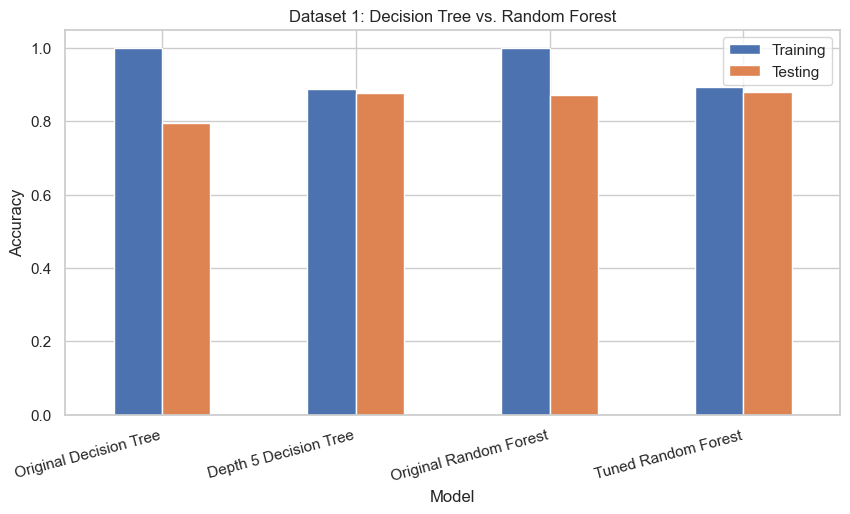

In [14]:
comparison1 = pd.DataFrame({
    "Model": ["Original Decision Tree", "Depth 5 Decision Tree", "Original Random Forest", "Tuned Random Forest"],
    "Training": [1.0, 0.8878, 1.0, 0.8931],
    "Testing": [0.7969, 0.8788, 0.8719, 0.8806]
})

comparison1.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Dataset 1: Decision Tree vs. Random Forest")
plt.ylabel("Accuracy")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.show()

Comparing the four models demonstrated the importance of controlling model complexity. The original Decision Tree achieved perfect training accuracy but only 79.69% testing accuracy, indicating substantial overfitting. Limiting the Decision Tree to a depth of 5 improved testing accuracy to 87.88%. Similarly, hyperparameter tuning improved the Random Forest's testing accuracy from 87.19% to 88.06%. The tuned Random Forest achieved the highest testing accuracy, although its improvement over the simpler Decision Tree was relatively small. These results suggest that limiting tree complexity can improve generalization.

### Dataset 1 Conclusion

Both Decision Tree and Random Forest models were used for predicting customer conversion, based on five marketing attributes. The first Decision Tree showed an extensive amount of overfitting, while reducing its depth increased the testing accuracy. The Random Forest showed better performance compared to the Decision Tree that was not constrained in depth. Hyperparameter optimization enhanced the accuracy of the Random Forest model to 88.06%. As for feature importance, AdSpend, ClickThroughRate, and TimeOnSite turned out to be the most important attributes. In conclusion, the best testing accuracy was achieved by the optimized Random Forest model. But since most customers got converted, the difference with the majority baseline was not large.

## Dataset 2: Marketing and Product Performance

### Data Preparation

The Marketing and Product Performance dataset contains 10,000 observations. Five marketing and product-related features will be used to predict whether a campaign achieves an above-median ROI. The dataset will be divided into 80% training and 20% testing, maintaining the same approach used for Dataset 1.

In [15]:
df2["High_ROI"] = (df2["ROI"] > df2["ROI"].median()).astype(int)

features2 = ["Budget", "Clicks", "Conversions", "Units_Sold", "Bundle_Price"]
X2 = df2[features2]
y2 = df2["High_ROI"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

print("Training:", X2_train.shape)
print("Testing:", X2_test.shape)
print("\nTarget Distribution:")
print(y2.value_counts())

Training: (8000, 5)
Testing: (2000, 5)

Target Distribution:
High_ROI
0    5002
1    4998
Name: count, dtype: int64


### Initial Decision Tree Model

A Decision Tree classifier was trained to predict whether a campaign achieves above-median ROI. The initial model has no restrictions on tree depth, allowing us to examine overfitting by comparing training and testing accuracy.

In [16]:
tree2 = DecisionTreeClassifier(random_state=42)
tree2.fit(X2_train, y2_train)

train_pred2 = tree2.predict(X2_train)
test_pred2 = tree2.predict(X2_test)

print("Training Accuracy:", round(accuracy_score(y2_train, train_pred2), 4))
print("Testing Accuracy:", round(accuracy_score(y2_test, test_pred2), 4))
print("Tree Depth:", tree2.get_depth())
print("Leaf Nodes:", tree2.get_n_leaves())

Training Accuracy: 1.0
Testing Accuracy: 0.5005
Tree Depth: 44
Leaf Nodes: 2214


The original decision tree model attained 100% training accuracy, while its testing accuracy was just 50.05%. The depth of the tree was 44, and the number of leaf nodes was 2,214. This implies that the model was very complicated. From the huge gap between training accuracy and testing accuracy, it is clear that there was high overfitting of the data. The model managed to classify all the training observations perfectly, but the testing accuracy was as good as random guessing.

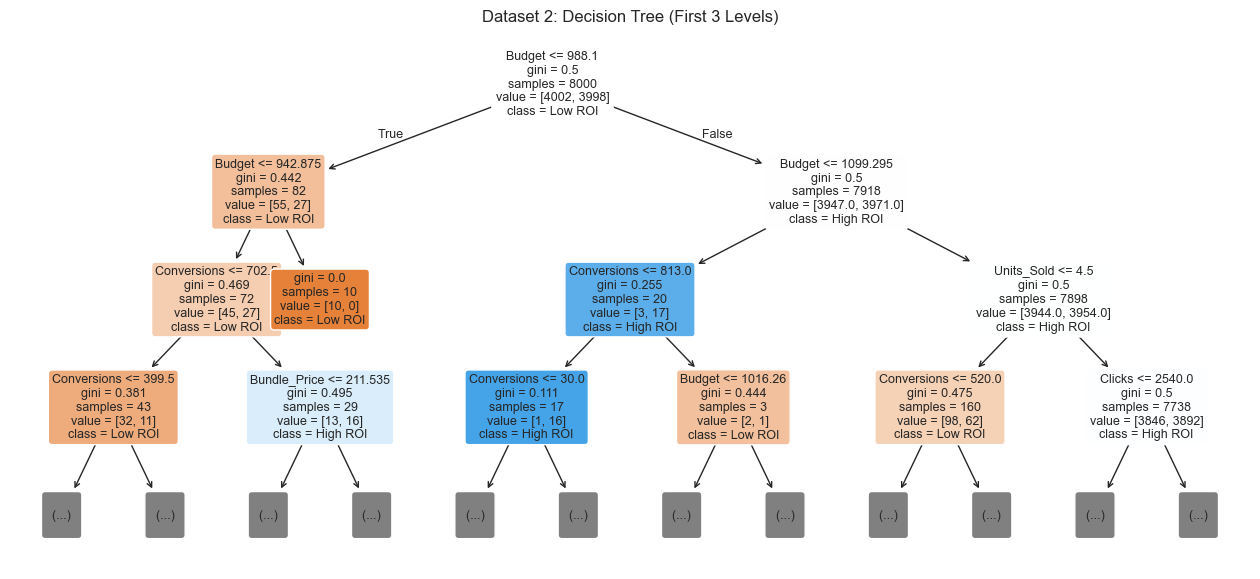

In [17]:
plt.figure(figsize=(16, 7))
plot_tree(tree2, feature_names=features2, class_names=["Low ROI", "High ROI"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Dataset 2: Decision Tree (First 3 Levels)")
plt.show()

In the Decision Tree, first split occurs based on Budget, and then splits are done based on various other factors such as Conversions, Units_Sold, Bundle_Price, and Clicks. High ROI and Low ROI classes exist in both the branches of the tree, which is because of the target variable being evenly distributed in the data. There exist some branches that have very little observations. The depth of tree is 44, and it is not accurate for testing.

### Decision Tree Depth Comparison

Different maximum tree depths were evaluated to examine how model complexity affects training and testing accuracy. This comparison helps determine whether limiting tree depth reduces overfitting and improves the model's ability to generalize.

In [18]:
depth_results2 = []

for depth in [2, 3, 5, 7, 10, 15, 20, 30]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X2_train, y2_train)

    depth_results2.append({
        "Depth": depth,
        "Training Accuracy": accuracy_score(y2_train, model.predict(X2_train)),
        "Testing Accuracy": accuracy_score(y2_test, model.predict(X2_test))
    })

depth_results2 = pd.DataFrame(depth_results2)
depth_results2.round(4)

,Depth,Training Accuracy,Testing Accuracy
0,2,0.5032,0.5005
1,3,0.5082,0.5065
2,5,0.5314,0.5050
3,7,0.5382,0.4900
4,10,0.5661,0.4930
5,15,0.6419,0.4890
6,20,0.7892,0.4900
7,30,0.9571,0.5010


When applying different values of maximum tree depth, we see that an increase in the complexity of our model does not have any substantial impact on the results. The maximum testing accuracy was recorded at depth 3 and amounted to 50.65%. When increasing the tree depth, the training accuracy was increasing up to 95.71% for tree depth 30, while the testing accuracy stayed around 50%. Thus, the increase in depth lead to overfitting of the model on training data.

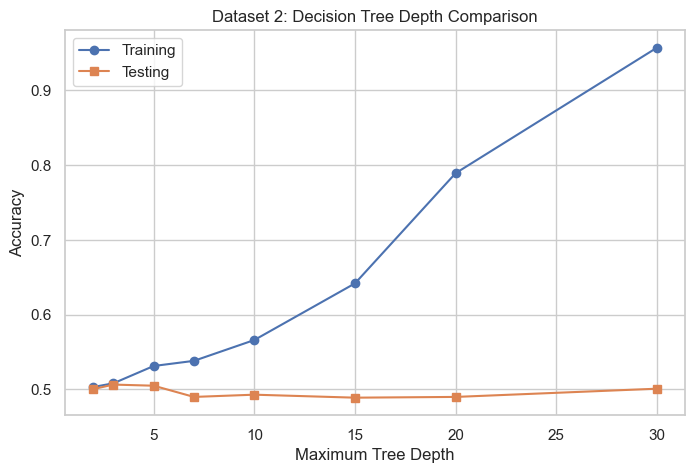

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(depth_results2["Depth"], depth_results2["Training Accuracy"], marker="o", label="Training")
plt.plot(depth_results2["Depth"], depth_results2["Testing Accuracy"], marker="s", label="Testing")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Dataset 2: Decision Tree Depth Comparison")
plt.legend()
plt.show()

### Random Forest Model

Random Forest Classifier was implemented using 100 decision trees that help identify if a campaign is above median return on investment. The implementation of Random Forest is meant to avoid the problem of high instability of Decision Trees by making a combination of several trees.

In [20]:
rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X2_train, y2_train)

rf_train_pred2 = rf2.predict(X2_train)
rf_test_pred2 = rf2.predict(X2_test)

print("Training Accuracy:", round(accuracy_score(y2_train, rf_train_pred2), 4))
print("Testing Accuracy:", round(accuracy_score(y2_test, rf_test_pred2), 4))
print("Precision:", round(precision_score(y2_test, rf_test_pred2), 4))
print("Recall:", round(recall_score(y2_test, rf_test_pred2), 4))
print("F1 Score:", round(f1_score(y2_test, rf_test_pred2), 4))

Training Accuracy: 1.0
Testing Accuracy: 0.5135
Precision: 0.5147
Recall: 0.473
F1 Score: 0.493


For the Random Forest, the accuracy obtained was 100% for training and 51.35% for testing, showing slight superiority to the Decision Tree algorithm with 50.05% and depth-limited Decision Tree with 50.65%. Also, Random Forest yielded an F1 score of 0.4930 with precision of 51.47% and recall of 47.30%. Despite the slight improvement in testing accuracy due to the combination of several trees, accuracy was still very close to what could be obtained by chance.

### Random Forest Feature Importance

Feature importance was examined to identify which marketing and product-related variables contributed most to the Random Forest's predictions.

In [21]:
importance2 = pd.DataFrame({
    "Feature": features2,
    "Importance": rf2.feature_importances_
}).sort_values("Importance", ascending=False)

importance2.round(4)

,Feature,Importance
1,Clicks,0.2075
0,Budget,0.2075
4,Bundle_Price,0.2072
2,Conversions,0.1992
3,Units_Sold,0.1786


### Feature Importance Findings

Importance of Random Forest was almost uniformly spread among all five predictors. Clicks and Budget have the maximum importance of 20.75% each; Bundle_Price has the third highest importance of 20.72%, followed by Conversions with 19.92% and Units_Sold with 17.86%. There is no dominating predictor in this model. But since testing accuracy is near 50%, it does not mean much.

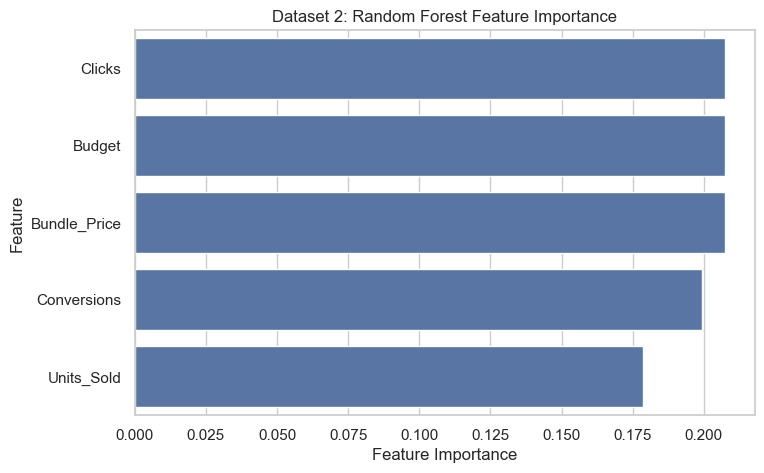

In [22]:
plt.figure(figsize=(8, 5))
sns.barplot(data=importance2, x="Importance", y="Feature")
plt.title("Dataset 2: Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

### Random Forest Hyperparameter Tuning

A GridSearchCV model with five-fold cross-validation was applied to test several settings of Random Forests. The number of trees, the maximum depth of the tree, and the number of samples in the leaves were tuned in order to see whether model simplicity helps to enhance the testing results. Accuracy is used for model comparison as the classes are approximately balanced.

In [23]:
param_grid2 = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10],
    "min_samples_leaf": [1, 5, 10]
}

grid2 = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid2, cv=5, scoring="accuracy", n_jobs=-1
)

grid2.fit(X2_train, y2_train)

print("Best Parameters:", grid2.best_params_)
print("Best Cross-Validation Accuracy:", round(grid2.best_score_, 4))

Best Parameters: {'max_depth': 5, 'min_samples_leaf': 10, 'n_estimators': 50}
Best Cross-Validation Accuracy: 0.5095


The results of GridSearchCV showed that the optimum values for depth, minimum samples per leaf, and number of trees were 5, 10, and 50, respectively. The cross-validation accuracy of the model was 50.95%. While the above mentioned settings make the model less complex, its accuracy level is similar to random guesses. This indicates that the chosen features give very little insight into above-median ROI of a campaign.

In [24]:
best_rf2 = grid2.best_estimator_
tuned_train_pred2 = best_rf2.predict(X2_train)
tuned_test_pred2 = best_rf2.predict(X2_test)

print("Training Accuracy:", round(accuracy_score(y2_train, tuned_train_pred2), 4))
print("Testing Accuracy:", round(accuracy_score(y2_test, tuned_test_pred2), 4))
print("Precision:", round(precision_score(y2_test, tuned_test_pred2), 4))
print("Recall:", round(recall_score(y2_test, tuned_test_pred2), 4))
print("F1 Score:", round(f1_score(y2_test, tuned_test_pred2), 4))

Training Accuracy: 0.5874
Testing Accuracy: 0.514
Precision: 0.5136
Recall: 0.53
F1 Score: 0.5217


Hyperparameter tuning had a small impact on improving testing accuracy to 51.40% compared to 51.35% and an increase in the F1 score from 0.4930 to 0.5217. Recall was also improved by hyperparameter tuning to 53.00% from 47.30%. Training accuracy dropped from 100% to 58.74%, demonstrating that overfitting is minimized with lower tree complexity. However, testing accuracy was not far from 50%.

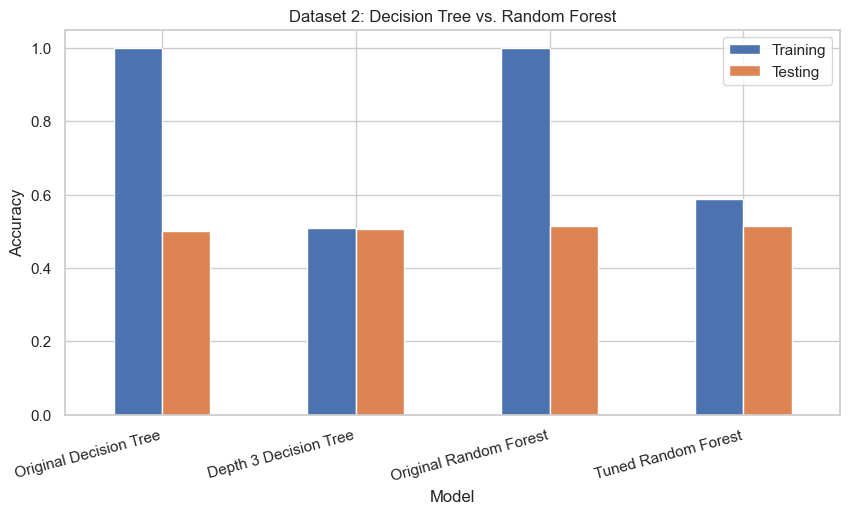

In [25]:
comparison2 = pd.DataFrame({
    "Model": ["Original Decision Tree", "Depth 3 Decision Tree", "Original Random Forest", "Tuned Random Forest"],
    "Training": [1.0, 0.5082, 1.0, 0.5874],
    "Testing": [0.5005, 0.5065, 0.5135, 0.5140]
})

comparison2.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Dataset 2: Decision Tree vs. Random Forest")
plt.ylabel("Accuracy")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.show()

The comparison of the four algorithms resulted in the conclusion that the Decision Tree and the Random Forest had significant overfitting issues; they scored 100% of training accuracy and approximately 50% of testing accuracy. The limiting of tree height and parameter adjustment of the Random Forest helped in decreasing the gap between the training and testing results. The adjusted Random Forest had the best testing accuracy score of 51.40%. But, as one can see, all four algorithms work approximately like random guessing.

### Dataset 2 Conclusion

The Decision Trees and the Random Forest approaches were considered in order to predict if the marketing campaigns had above-median ROI. While the initial Decision Tree exhibited heavy overfitting, the decreased depth of the tree was able to reduce the complexity of the model without increasing prediction power significantly. The Random Forest performed slightly better than the Decision Trees and hyperparameter tuning allowed to increase the testing accuracy up to 51.40%. It is worth noting that all five input variables had more or less equal importance for the prediction model.

## Dataset 3: Synthetic B2B CRM & Marketing

### Data Preparation

Synthetic B2B CRM & Marketing dataset has 734 records. Four business features will be used to determine if there is an Active contract in place. The data will be split into 80 percent training and 20 percent testing data using stratified sampling method.

In [26]:
df3["Active_Contract"] = (df3["Contract_Status"] == "Active").astype(int)

features3 = ["Annual_Revenue (M₺)", "Marketing_Spend (K₺)",
             "Days_Since_Last_Purchase", "Total_Purchases_Last_Year"]

X3 = df3[features3]
y3 = df3["Active_Contract"]

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3
)

print("Training:", X3_train.shape)
print("Testing:", X3_test.shape)
print("\nTarget Distribution:")
print(y3.value_counts())

Training: (587, 4)
Testing: (147, 4)

Target Distribution:
Active_Contract
1    528
0    206
Name: count, dtype: int64


### Initial Decision Tree Model

A Decision Tree classifier was trained using four business-related features to predict contract status. The initial model does not restrict tree depth, allowing us to compare training and testing performance and examine potential overfitting.

In [27]:
tree3 = DecisionTreeClassifier(random_state=42)
tree3.fit(X3_train, y3_train)

train_pred3 = tree3.predict(X3_train)
test_pred3 = tree3.predict(X3_test)

print("Training Accuracy:", round(accuracy_score(y3_train, train_pred3), 4))
print("Testing Accuracy:", round(accuracy_score(y3_test, test_pred3), 4))
print("Tree Depth:", tree3.get_depth())
print("Leaf Nodes:", tree3.get_n_leaves())

Training Accuracy: 1.0
Testing Accuracy: 0.585
Tree Depth: 25
Leaf Nodes: 182


The first decision tree was able to achieve a perfect level of accuracy during training, which was 100%. However, its accuracy during the testing phase was much lower – 58.50%. The tree was deep enough, since it reached a depth of 25 levels and contained 182 leaf nodes. Large discrepancy in the results shows that there is significant overfitting in the model. Also, testing accuracy of the model is lower than majority class baseline (72%).

/Users/staghetti/Library/Python/3.9/lib/python/site-packages/sklearn/tree/_export.py:673: UserWarning: Glyph 8378 (\N{TURKISH LIRA SIGN}) missing from font(s) Arial.
  ann.update_bbox_position_size(renderer)
/Users/staghetti/Library/Python/3.9/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8378 (\N{TURKISH LIRA SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


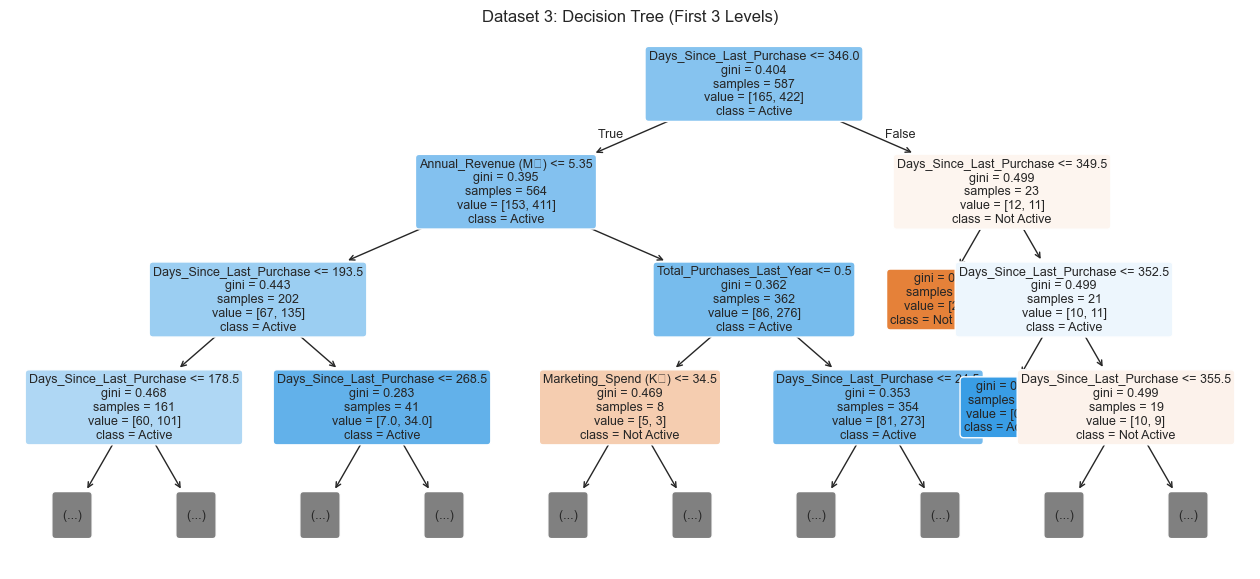

In [28]:
plt.figure(figsize=(16, 7))
plot_tree(tree3, feature_names=features3, class_names=["Not Active", "Active"],
          filled=True, rounded=True, max_depth=3, fontsize=9)
plt.title("Dataset 3: Decision Tree (First 3 Levels)")
plt.show()

Decision Tree starts with the split according to the feature Days_Since_Last_Purchase and then proceeds with splits according to Annual_Revenue, Total_Purchases_Last_Year and Marketing_Spend. In general, the larger branches tend to predict Active state due to imbalanced classes in the dataset. At the same time, there are several branches which have a small number of observations. Together with the model depth of 25 and low testing accuracy, this indicates the need for restricting tree complexity.

### Decision Tree Depth Comparison

Different maximum tree depths were evaluated to examine how model complexity affects training and testing accuracy. This comparison helps determine whether limiting tree depth reduces overfitting and improves generalization.

In [29]:
depth_results3 = []

for depth in [2, 3, 5, 7, 10, 15, 20, 30]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X3_train, y3_train)

    depth_results3.append({
        "Depth": depth,
        "Training Accuracy": accuracy_score(y3_train, model.predict(X3_train)),
        "Testing Accuracy": accuracy_score(y3_test, model.predict(X3_test))
    })

depth_results3 = pd.DataFrame(depth_results3)
depth_results3.round(4)

,Depth,Training Accuracy,Testing Accuracy
0,2,0.7223,0.7211
1,3,0.7274,0.7007
2,5,0.7445,0.7007
3,7,0.7905,0.7007
4,10,0.8535,0.6531
5,15,0.9625,0.5714
6,20,0.9949,0.5782
7,30,1.0000,0.5850


Various maximum tree depths were tested to see how model complexity can cause overfitting. Maximum tree depth of 2 gave the best test accuracy which was 72.11%, and increasing depth resulted in decreased test accuracy. Training accuracy grew from 72.23% for maximum tree depth of 2 to 100% for maximum tree depth of 30, while test accuracy fell to 58.50%. Thus, more complex trees learned too specific patterns which failed to generalize. Despite the reduction in overfitting caused by smaller tree depths, the best test accuracy matched the majority class baseline.

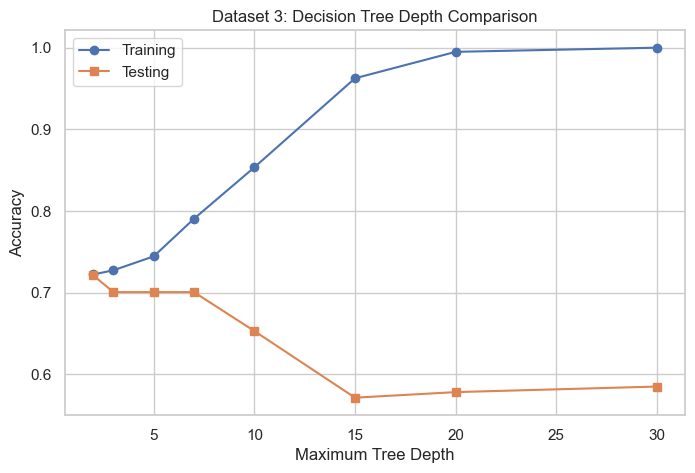

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(depth_results3["Depth"], depth_results3["Training Accuracy"], marker="o", label="Training")
plt.plot(depth_results3["Depth"], depth_results3["Testing Accuracy"], marker="s", label="Testing")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Dataset 3: Decision Tree Depth Comparison")
plt.legend()
plt.show()

### Random Forest Model

Random Forest model was used to predict whether contracts are active or not. It was trained with 100 decision trees. Random Forest tries to decrease the possibility of overfitting, and it is supposed to have better performance than single Decision Tree. Performance of the training set and testing set was measured to compare results.

In [31]:
rf3 = RandomForestClassifier(n_estimators=100, random_state=42)
rf3.fit(X3_train, y3_train)

rf_train_pred3 = rf3.predict(X3_train)
rf_test_pred3 = rf3.predict(X3_test)

print("Training Accuracy:", round(accuracy_score(y3_train, rf_train_pred3), 4))
print("Testing Accuracy:", round(accuracy_score(y3_test, rf_test_pred3), 4))
print("Precision:", round(precision_score(y3_test, rf_test_pred3), 4))
print("Recall:", round(recall_score(y3_test, rf_test_pred3), 4))
print("F1 Score:", round(f1_score(y3_test, rf_test_pred3), 4))

Training Accuracy: 1.0
Testing Accuracy: 0.6599
Precision: 0.7154
Recall: 0.8774
F1 Score: 0.7881


In the case of the Random Forest algorithm, we have obtained 100% accuracy on training data and 65.99% accuracy on testing data, which is higher compared to the testing accuracy of the base Decision Tree, which was equal to 58.50%. The precision is equal to 71.54%, recall is equal to 87.74%, and F1 score is 0.7881. While using several trees made it possible to improve the results compared to the unrestricted Decision Tree, the Random Forest still performs worse than the Decision Tree with limited depth.

### Random Forest Feature Importance

Feature importance was examined to identify which business-related variables contributed most to the Random Forest's predictions of contract status.

In [32]:
importance3 = pd.DataFrame({
    "Feature": features3,
    "Importance": rf3.feature_importances_
}).sort_values("Importance", ascending=False)

importance3.round(4)

,Feature,Importance
0,Annual_Revenue (M₺),0.3211
2,Days_Since_Last_Purchase,0.3007
1,Marketing_Spend (K₺),0.2238
3,Total_Purchases_Last_Year,0.1543


Random Forest feature importance showed that Annual_Revenue (32.11%) and Days_Since_Last_Purchase (30.07%) were the most influential predictors of contract status. Together, they accounted for approximately 62% of total feature importance. Marketing_Spend contributed 22.38%, while Total_Purchases_Last_Year had the lowest importance at 15.43%. Although these variables contributed to the model's decisions, the relatively low testing accuracy suggests that their predictive value may be limited.

/Users/staghetti/Library/Python/3.9/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8378 (\N{TURKISH LIRA SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


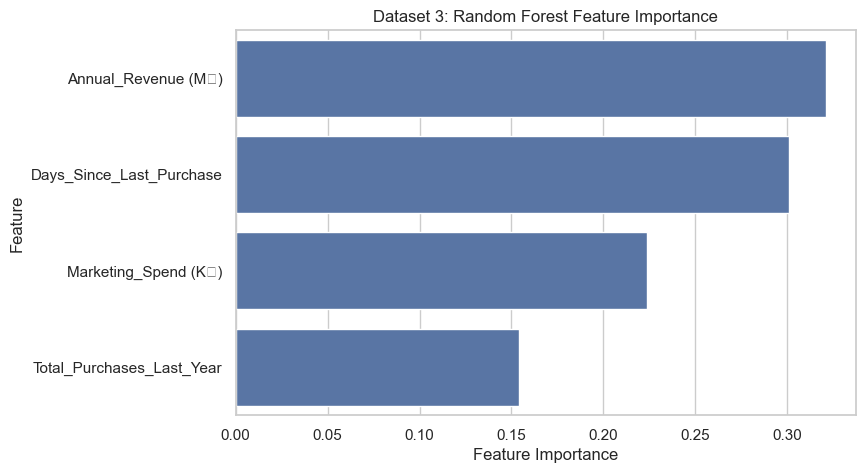

In [33]:
plt.figure(figsize=(8, 5))
sns.barplot(data=importance3, x="Importance", y="Feature")
plt.title("Dataset 3: Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

### Random Forest Hyperparameter Tuning

GridSearchCV with 5-fold cross validation has been implemented to test the various parameters of Random Forest algorithm. The various parameters like number of trees, maximum tree depth, and minimum samples at the leaf nodes have been tuned to overcome over-fitting problem. F1 score has been calculated for evaluation purpose.

In [34]:
param_grid3 = {
    "n_estimators": [50, 100],
    "max_depth": [3, 5, 10],
    "min_samples_leaf": [1, 5, 10]
}

grid3 = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid3, cv=5, scoring="f1", n_jobs=-1
)

grid3.fit(X3_train, y3_train)

print("Best Parameters:", grid3.best_params_)
print("Best Cross-Validation F1:", round(grid3.best_score_, 4))

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 50}
Best Cross-Validation F1: 0.8361


From the GridSearchCV function, the optimal parameters for the Random Forest were found as follows: maximum depth of 3, minimum of 10 samples per leaf and 50 trees. The F1 score obtained was 0.8361 from the cross-validation process. The parameters used above will ensure that the trees remain simple and help avoid overfitting. Nevertheless, since there are more Active than Not Active contracts in the dataset, more tests need to be performed.

In [35]:
best_rf3 = grid3.best_estimator_
tuned_train_pred3 = best_rf3.predict(X3_train)
tuned_test_pred3 = best_rf3.predict(X3_test)

print("Training Accuracy:", round(accuracy_score(y3_train, tuned_train_pred3), 4))
print("Testing Accuracy:", round(accuracy_score(y3_test, tuned_test_pred3), 4))
print("Precision:", round(precision_score(y3_test, tuned_test_pred3), 4))
print("Recall:", round(recall_score(y3_test, tuned_test_pred3), 4))
print("F1 Score:", round(f1_score(y3_test, tuned_test_pred3), 4))

Training Accuracy: 0.7189
Testing Accuracy: 0.7211
Precision: 0.7211
Recall: 1.0
F1 Score: 0.8379


The tuning of hyperparameters helped increase the accuracy of testing to 72.11% from 65.99% and also improved the F1 score to 0.8379 from 0.7881. The accuracy of training dropped from 100% to 71.89% due to the fact that constraining the tree helped reduce the case of overfitting. It can be seen that the tuned model tends to predict all observations as active.

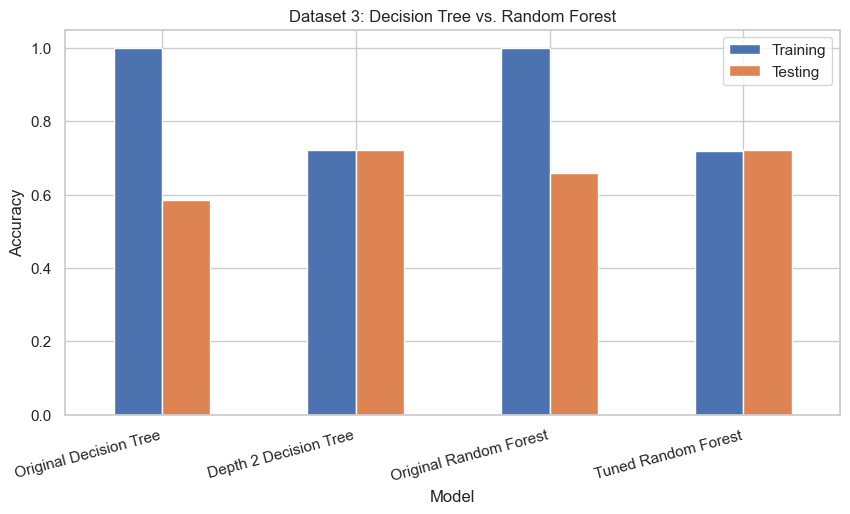

In [36]:
comparison3 = pd.DataFrame({
    "Model": ["Original Decision Tree", "Depth 2 Decision Tree", "Original Random Forest", "Tuned Random Forest"],
    "Training": [1.0, 0.7223, 1.0, 0.7189],
    "Testing": [0.5850, 0.7211, 0.6599, 0.7211]
})

comparison3.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Dataset 3: Decision Tree vs. Random Forest")
plt.ylabel("Accuracy")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.show()

The comparison of the four models showed how overfitting can be harmful. For instance, for the initial Decision Tree, there was 100% training accuracy, but the testing accuracy was only 58.50%, and the testing accuracy for the initial Random Forest was 65.99%. Reducing the number of levels for the tree and fine-tuning of the parameters of the Random Forest increased testing accuracy up to 72.11%. Nevertheless, the highest testing accuracy was equal to the baseline value, which means that the models cannot make any differentiation.

### Dataset 3 Conclusion

Decision Trees and Random Forests were tested on predicting whether the company had an active contract based on four business-oriented attributes. The original algorithms showed significant overfitting problems, whereas constraining the trees' depth helped overcome this problem. Tuning the Random Forest resulted in an accuracy of 72.11% for testing, which is equivalent to the accuracy of the constrained Decision Tree. The importance analysis revealed that Annual_Revenue and Days_Since_Last_Purchase were the most important features. While tuning decreased the problem of overfitting, the final algorithm mainly predicted the Active contracts.

## Conclusion

Week 6 involved applying Decision Trees and Random Forests to three datasets in order to analyze the performance of the classifier, overfitting, and feature importance. The various depths of trees were analyzed, and GridSearchCV was utilized for hyperparameter tuning of Random Forest. All three datasets showed that unrestricted Decision Trees and Random Forests achieved 100% training accuracy but had poor performance on testing data. Reducing the maximum depth of the tree and tuning hyperparameters helped reduce the problem of overfitting and improve the testing performance. The best performance out of the three datasets came from Dataset 1, where the tuned Random Forest gave 88.06% testing accuracy. The second dataset again showed poor predictive performance, giving 51.40% testing accuracy. The third dataset achieved 72.11% testing accuracy; however, this was equivalent to the majority class baseline of the dataset. The analysis of feature importance helped identify the most important variables in making the predictions. However, the analysis also showed that there is no correlation between the feature importance and the predictive performance of the model.